<a href="https://colab.research.google.com/github/bounouarafarah/OIBSIP/blob/main/spam_detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

(5572, 2)
label      0
message    0
dtype: int64
label
ham     4825
spam     747
Name: count, dtype: int64
label
ham     86.6
spam    13.4
Name: proportion, dtype: float64


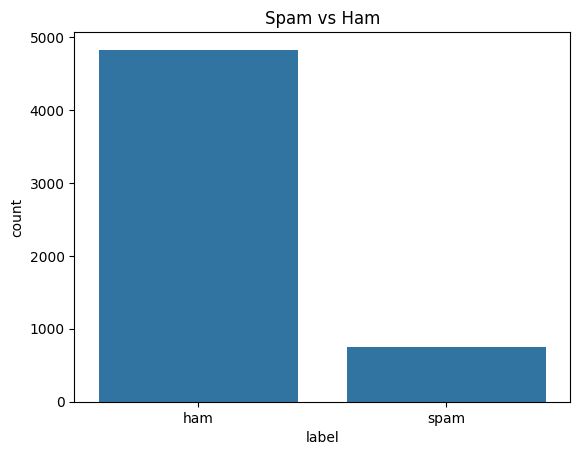

,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [11]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns

url = "https://raw.githubusercontent.com/justmarkham/pycon-2016-tutorial/master/data/sms.tsv"
df = pd.read_csv(url, sep="\t", header=None, names=["label", "message"])

print(df.shape)
print(df.isnull().sum())
print(df["label"].value_counts())
print((df["label"].value_counts(normalize=True) * 100).round(1))

sns.countplot(data=df, x="label")
plt.title("Spam vs Ham"); plt.show()
df.head()

## Observations: class distribution

- There are 4,825 ham messages and 747 spam messages, so spam is only 13.4% of the dataset.
- The classes are imbalanced.
- A model that always predicts "ham" would already get 86.6% accuracy, so accuracy alone is not enough. I will also look at precision, recall and F1 for the spam class.

In [12]:
import re, nltk
nltk.download("stopwords")
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer

stop_words = set(stopwords.words("english"))
stemmer = PorterStemmer()

def clean_text(text):
    text = text.lower()
    text = re.sub(r"[^a-z\s]", " ", text)
    words = [stemmer.stem(w) for w in text.split() if w not in stop_words]
    return " ".join(words)

df["clean"] = df["message"].apply(clean_text)
df[["message", "clean"]].head()

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


,message,clean
0,"Go until jurong point, crazy.. Available only ...",go jurong point crazi avail bugi n great world...
1,Ok lar... Joking wif u oni...,ok lar joke wif u oni
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entri wkli comp win fa cup final tkt st m...
3,U dun say so early hor... U c already then say...,u dun say earli hor u c alreadi say
4,"Nah I don't think he goes to usf, he lives aro...",nah think goe usf live around though


In [13]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

X_train_txt, X_test_txt, y_train, y_test = train_test_split(
    df["clean"], df["label"], test_size=0.2, random_state=42, stratify=df["label"])

tfidf = TfidfVectorizer(max_features=3000)
X_train = tfidf.fit_transform(X_train_txt)   # apprend le vocabulaire sur le train seulement
X_test = tfidf.transform(X_test_txt)

print(X_train.shape, X_test.shape)

(4457, 3000) (1115, 3000)


## TF-IDF

TF-IDF (Term Frequency - Inverse Document Frequency) measures how important a word is in a message relative to the whole collection of messages. A word that appears often in one message (high TF) but rarely in the other messages (high IDF), like "free" or "prize" in spam, gets a high weight. Very common words get a low weight. This turns each text into a numeric vector that a machine learning model can use.

===== Multinomial Naive Bayes =====
              precision    recall  f1-score   support

         ham       0.97      1.00      0.99       966
        spam       0.99      0.83      0.90       149

    accuracy                           0.98      1115
   macro avg       0.98      0.91      0.94      1115
weighted avg       0.98      0.98      0.97      1115



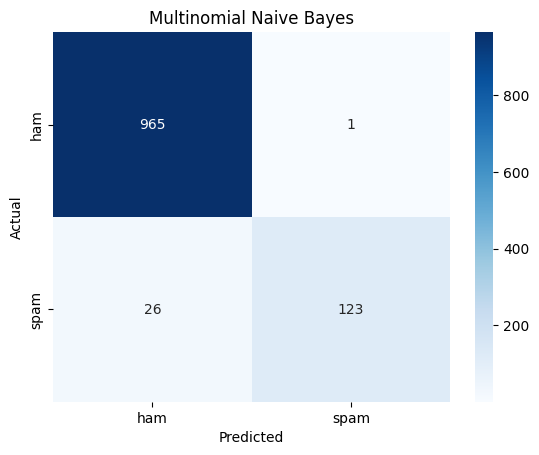

===== Logistic Regression =====
              precision    recall  f1-score   support

         ham       0.97      1.00      0.98       966
        spam       1.00      0.79      0.88       149

    accuracy                           0.97      1115
   macro avg       0.98      0.90      0.93      1115
weighted avg       0.97      0.97      0.97      1115



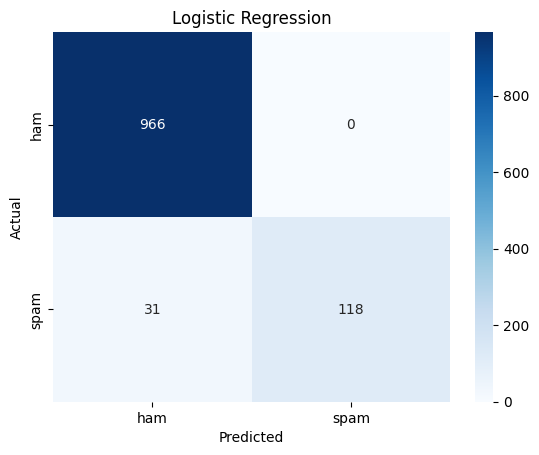

,Model,Accuracy,Precision (spam),Recall (spam),F1 (spam)
0,Multinomial Naive Bayes,0.976,0.992,0.826,0.901
1,Logistic Regression,0.972,1.000,0.792,0.884


In [14]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

models = {
    "Multinomial Naive Bayes": MultinomialNB(),
    "Logistic Regression": LogisticRegression(max_iter=1000),
}

rows = []
for name, m in models.items():
    m.fit(X_train, y_train)
    pred = m.predict(X_test)
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision (spam)": precision_score(y_test, pred, pos_label="spam"),
        "Recall (spam)": recall_score(y_test, pred, pos_label="spam"),
        "F1 (spam)": f1_score(y_test, pred, pos_label="spam"),
    })
    print("=====", name, "=====")
    print(classification_report(y_test, pred))
    sns.heatmap(confusion_matrix(y_test, pred, labels=["ham", "spam"]),
                annot=True, fmt="d", cmap="Blues",
                xticklabels=["ham", "spam"], yticklabels=["ham", "spam"])
    plt.title(name); plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.show()

pd.DataFrame(rows).round(3)

## Observations: Multinomial Naive Bayes

- Out of 149 spam messages in the test set, the model detected 123 and missed 26, so its recall for spam is about 0.83.
- It wrongly classified only 1 legitimate message as spam, so its precision for spam is very high (about 0.99).
- Missing 26 spams means 26 unwanted messages reach the user.

## Observations: Logistic Regression

- No legitimate message was wrongly blocked (0 false positives), so the precision for spam is 1.00.
- However, the model missed 31 spam messages out of 149 and detected 118, so its recall for spam is only about 0.79.
- Compared with Naive Bayes (26 spams missed, 1 legitimate message blocked), Logistic Regression is the safer model for legitimate messages but lets more spam through.


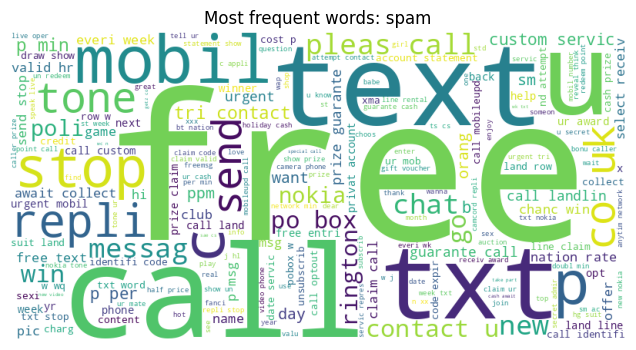

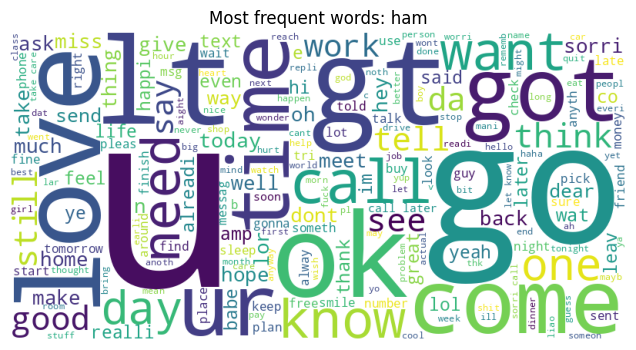

In [15]:
from wordcloud import WordCloud

for lab in ["spam", "ham"]:
    text = " ".join(df[df["label"] == lab]["clean"])
    wc = WordCloud(width=800, height=400, background_color="white").generate(text)
    plt.figure(figsize=(9, 4)); plt.imshow(wc); plt.axis("off")
    plt.title(f"Most frequent words: {lab}"); plt.show()

## Observations: word clouds

- The biggest words in spam messages are [call, free, txt, mobil, claim]. They push the reader to act or promise a reward, which is typical of promotional and scam messages.
- The most frequent words in ham messages are [u, go, get, ok, come]. They are everyday conversation words, with no sales or urgency vocabulary.
- This explains why TF-IDF works well here: spam-specific words get a high weight in spam and a low weight in ham, so the models can separate the two classes.

## Results and discussion

| Model | Accuracy | Precision (spam) | Recall (spam) | F1 (spam) |
|---|---|---|---|---|
| Multinomial Naive Bayes | 0.976 | 0.992 | 0.826 | 0.901 |
| Logistic Regression | 0.972 | 1.000 | 0.792 | 0.884 |

**Why is recall especially important for spam detection?**
Recall measures the share of real spam messages that the model catches. A missed spam (false negative) lands in the user's inbox, where it can be a phishing attempt or a scam. Logistic Regression missed 31 of 149 spam messages, Naive Bayes missed 26. The trade-off is precision: blocking a legitimate message (false positive) is also costly, and Logistic Regression never did it while Naive Bayes did it once.

**Class imbalance:** only 13.4% of the messages are spam, so accuracy alone is misleading (always answering "ham" gives 86.6%). I therefore compared the models on precision, recall and F1 for the spam class.

**Best model: Multinomial Naive Bayes.** It has the higher recall (0.826 vs 0.792), the higher F1 (0.901 vs 0.884) and the highest accuracy, with only one legitimate message blocked. It is also fast to train, which is why it is the standard choice for text classification.